In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import torch

from utils import block_diag, interleave

In [2]:
def func(x, y, c, l): # correlation function
    return np.sum((c**2)[:,None]*np.cos(l[:,0][:,None]*x[None] + l[:,1][:,None]*y[None]), axis = 0)

In [3]:
N = 256

In [11]:
super_diags = torch.tensor(np.random.normal(0, 0.2, (N//2, 2)).astype(np.float32))
sA = block_diag(super_diags[:,0])
sB = block_diag(super_diags[:,1])

lx = interleave(super_diags[:,0], -super_diags[:,0])
ly = interleave(super_diags[:,1], -super_diags[:,1])
eigenvals = torch.stack((lx, ly), dim = -1)

u = (torch.rand((N, N)).to(torch.float32) - 0.5)*2 # random
Gr = u - u.T # skew symmetric
R = torch.matrix_exp(Gr) # orthogonal, s = 1

p0 = R.T@torch.tensor(np.ones(len(R)).astype(np.float32))
c = torch.ones(N)

(np.float64(-0.7480640649795532),
 np.float64(0.7480640649795532),
 np.float64(-0.5405615419149399),
 np.float64(0.5405615419149399))

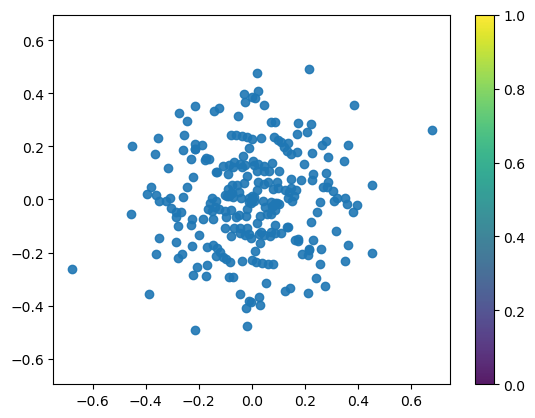

In [12]:
plt.scatter(eigenvals[:,0].detach().numpy(), eigenvals[:,1].detach().numpy(), alpha=0.9)
plt.colorbar()
plt.axis("equal")

In [6]:
torch.save(sA, "sigma_A.pt")
torch.save(sB, "sigma_B.pt")
torch.save(Gr, "Gr.pt")
torch.save(p0, "p0.pt")

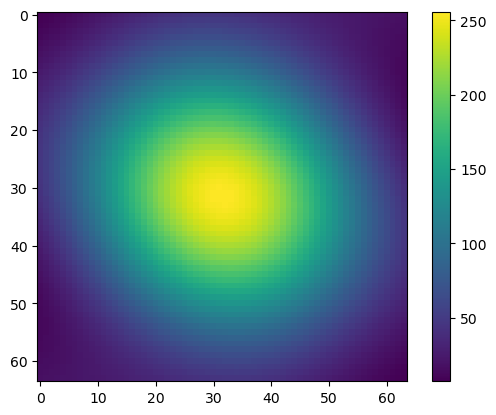

In [7]:
x = np.linspace(-1, 1, 64)*10
y = np.linspace(-1, 1, 64)*10
X, Y = np.meshgrid(x, y)
r = np.stack([X.ravel(), Y.ravel()], axis=1)
d = func(r[:,0], r[:,1], c.numpy(), eigenvals.numpy())

plt.imshow(d.reshape(X.shape))
plt.colorbar()